In [2]:
# Import os, a Python library used to interact with folders and files.
import os

# Define the main project directory.
project_path = "/content/scope3-procurement-matching"

# Define the subfolders we need for the project.
folders = [
    "data/raw",
    "data/processed",
    "data/reference",
    "notebooks",
    "src",
    "results"
]

# Create the main directory and all its subfolders.
# exist_ok=True prevents an error if a folder already exists.
for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

# Display a confirmation.
print("Project structure successfully created!")

Project structure successfully created!


In [3]:
import pandas as pd

# NB These are fictional records created with an LLM (GPT-6) exclusively for this project.
# Since I had no accesso to real ETH procurement records, those are created to
# resemble the kind of information a procurement system might contain.
# I asked the LLM to deliberately include variations in wording, spelling and descriptions.
# This is important because the matching methods need to handle imperfect real-world text.


procurement_data = {

    "transaction_id": [
        f"TR{i:03d}" for i in range(1, 26) #automatically generates transaction IDs
    ],

    "description": [
        "Laptop computer Lenovo ThinkPad",
        "Purchase of notebook computers",
        "Office desk wooden",
        "Ergonomic office chair",
        "Diesel fuel for company vehicles",
        "Printer paper A4 80gsm",
        "Copy paper for office printers",
        "Cloud software subscription",
        "IT consulting services",
        "Business travel by train",
        "Hotel accommodation employees",
        "Office cleaning services",
        "Electricity for office building",
        "Mobile phone devices",
        "Computer monitor 27 inch",
        "Office furniture cabinets",
        "Purchase of laptops for staff",
        "Petrol for company cars",
        "Printer toner cartridges",
        "Waste collection services",
        "Professional legal consulting",
        "Data storage cloud services",
        "Office stationery supplies",
        "Business travel by airplane",
        "Maintenance of office equipment"
    ],

    "supplier": [
        "Tech Solutions AG",
        "Digital Systems GmbH",
        "Office Design SA",
        "Workplace Solutions AG",
        "Fuel Partners GmbH",
        "Paper World AG",
        "Office Supplies SA",
        "Cloud Services Ltd",
        "Consulting Partners AG",
        "Swiss Rail Services",
        "Hotel Group AG",
        "Clean Solutions GmbH",
        "Energy Provider AG",
        "Mobile Tech SA",
        "Digital Systems GmbH",
        "Office Design SA",
        "Tech Solutions AG",
        "Fuel Partners GmbH",
        "Print Solutions AG",
        "Waste Management AG",
        "Legal Partners SA",
        "Cloud Services Ltd",
        "Office Supplies SA",
        "Travel Services AG",
        "Technical Maintenance GmbH"
    ],

    "amount": [
        1450, 3200, 850, 420, 780, 120, 95, 2400, 5500,
        180, 950, 600, 4200, 1100, 380, 1250, 2900, 650,
        230, 480, 3200, 1750, 160, 2200, 890
    ],

    "currency": ["CHF"] * 25,

    "procurement_date": [
        "2026-01-15", "2026-02-10", "2026-02-12",
        "2026-02-20", "2026-03-01", "2026-03-05",
        "2026-03-08", "2026-03-15", "2026-03-20",
        "2026-04-02", "2026-04-10", "2026-04-15",
        "2026-04-20", "2026-05-01", "2026-05-04",
        "2026-05-10", "2026-05-15", "2026-05-20",
        "2026-06-01", "2026-06-05", "2026-06-10",
        "2026-06-15", "2026-06-20", "2026-07-01",
        "2026-07-05"
    ],

    "country": ["Switzerland"] * 25
}

# Convert the dictionary into a Pandas DataFrame.
procurement_df = pd.DataFrame(procurement_data)

# Convert procurement_date from text into a proper date format.
procurement_df["procurement_date"] = pd.to_datetime(
    procurement_df["procurement_date"]
)

# Display the first five transactions.
print(procurement_df.head())

  transaction_id                       description                supplier  \
0          TR001   Laptop computer Lenovo ThinkPad       Tech Solutions AG   
1          TR002    Purchase of notebook computers    Digital Systems GmbH   
2          TR003                Office desk wooden        Office Design SA   
3          TR004            Ergonomic office chair  Workplace Solutions AG   
4          TR005  Diesel fuel for company vehicles      Fuel Partners GmbH   

   amount currency procurement_date      country  
0    1450      CHF       2026-01-15  Switzerland  
1    3200      CHF       2026-02-10  Switzerland  
2     850      CHF       2026-02-12  Switzerland  
3     420      CHF       2026-02-20  Switzerland  
4     780      CHF       2026-03-01  Switzerland  


In [4]:
# Display the number of rows and columns.
print("Dataset dimensions:", procurement_df.shape)

# Display the column names.
print("\nColumn names:")
print(procurement_df.columns)

# Check data types and missing values.
print("\nDataset information:")
procurement_df.info()

# Calculate basic statistics for numerical columns.
print("\nDescriptive statistics:")
print(procurement_df.describe())

Dataset dimensions: (25, 7)

Column names:
Index(['transaction_id', 'description', 'supplier', 'amount', 'currency',
       'procurement_date', 'country'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    25 non-null     object        
 1   description       25 non-null     object        
 2   supplier          25 non-null     object        
 3   amount            25 non-null     int64         
 4   currency          25 non-null     object        
 5   procurement_date  25 non-null     datetime64[ns]
 6   country           25 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 1.5+ KB

Descriptive statistics:
            amount     procurement_date
count    25.000000                   25
mean   1437.400000  2026-04-19 00:00:0

In [5]:
# Define where the CSV file should be saved.
file_path = os.path.join(
    project_path,
    "data",
    "raw",
    "procurement_data.csv"
)

# Export the DataFrame to CSV.
# index=False prevents Pandas from adding an unnecessary row index.
procurement_df.to_csv(file_path, index=False)

print("Dataset saved successfully!")
print("File location:", file_path)

Dataset saved successfully!
File location: /content/scope3-procurement-matching/data/raw/procurement_data.csv


In [6]:
import requests
import os

# Official download link for the corrected USEEIO v2.5.1 model.
url = (
    "https://pasteur.epa.gov/uploads/10.23719/1532304/"
    "USEEIOv2.5.1-waxwing-22.xlsx"
)

# Define the destination inside our raw data folder.
file_path = os.path.join(
    project_path,
    "data",
    "raw",
    "emission_factors.xlsx"
)

# Download the file from the EPA server.
response = requests.get(url, timeout=120)

# Raise an error if the download was unsuccessful.
response.raise_for_status()

# Save the downloaded Excel file locally in Colab.
with open(file_path, "wb") as file:
    file.write(response.content)

In [7]:
import pandas as pd

# Open the Excel workbook without loading all its data.
# ExcelFile allows us to inspect its structure first.
excel_file = pd.ExcelFile(file_path)

# Retrieve the names of all worksheets in the workbook.
sheet_names = excel_file.sheet_names

# Display the available worksheets.
print("Number of worksheets:", len(sheet_names))

print("\nAvailable worksheets:")

for sheet in sheet_names:
    print("-", sheet)

Number of worksheets: 33

Available worksheets:
- V
- U
- U_d
- A
- A_d
- A_m
- B
- C
- D
- L
- L_d
- M
- M_d
- M_m
- N
- N_d
- N_m
- Rho
- Phi
- Tau
- q
- x
- 2017_US_Production_Complete
- 2017_US_Production_Domestic
- 2017_US_Consumption_Complete
- 2017_US_Consumption_Domestic
- demands
- flows
- indicators
- commodities_meta
- final_demand_meta
- value_added_meta
- SectorCrosswalk


In [8]:
# Load the commodity metadata worksheet.
# It should contain information describing the model's economic sectors.
sector_df = pd.read_excel(
    file_path,
    sheet_name="commodities_meta"
)

# Display the first five rows.
print("FIRST FIVE ROWS:")
print(sector_df.head())

# Display all column names.
print("\nCOLUMN NAMES:")
print(sector_df.columns.tolist())

# Display the number of rows and columns.
print("\nDIMENSIONS:")
print(sector_df.shape)

# Check the data types and missing values.
print("\nDATASET INFORMATION:")
sector_df.info()

FIRST FIVE ROWS:
   Index         ID                                               Name  \
0      0  1111A0/US  Fresh soybeans, canola, flaxseeds, and other o...   
1      1  1111B0/US          Fresh wheat, corn, rice, and other grains   
2      2  111200/US             Fresh vegetables, melons, and potatoes   
3      3  111300/US                         Fresh fruits and tree nuts   
4      4  111400/US  Greenhouse crops, mushrooms, nurseries, and fl...   

     Code Location                                           Category  \
0  1111A0       US  11: Agriculture, Forestry, Fishing and Hunting...   
1  1111B0       US  11: Agriculture, Forestry, Fishing and Hunting...   
2  111200       US  11: Agriculture, Forestry, Fishing and Hunting...   
3  111300       US  11: Agriculture, Forestry, Fishing and Hunting...   
4  111400       US  11: Agriculture, Forestry, Fishing and Hunting...   

                                         Description Unit  
0  BEA Code & Name is 1111A0:Oilseed fa

In [9]:
# Load the environmental indicators metadata.
indicators_df = pd.read_excel(
    file_path,
    sheet_name="indicators"
)

# Display the available environmental indicators.
print(indicators_df.head(15))

# Display their column names.
print("\nCOLUMN NAMES:")
print(indicators_df.columns.tolist())

# Display the dimensions.
print("\nDIMENSIONS:")
print(indicators_df.shape)

   Index                                ID                    Name  \
0      0      Material Footprint/MF-Bio/kg       Biomass Footprint   
1      1   Material Footprint/MF-Fossil/kg  Fossil Fuels Footprint   
2      2    Impact Potential/GHG/kg CO2 eq        Greenhouse Gases   
3      3    Material Footprint/MF-Metal/kg        Metals Footprint   
4      4  Material Footprint/MF-Mineral/kg      Minerals Footprint   

         Code       Unit               Group                      SimpleUnit  \
0      MF-Bio         kg  Material Footprint                             NaN   
1   MF-Fossil         kg  Material Footprint                             NaN   
2         GHG  kg CO2 eq    Impact Potential  Kilograms Carbon Dioxide (CO2)   
3    MF-Metal         kg  Material Footprint                             NaN   
4  MF-Mineral         kg  Material Footprint                             NaN   

         SimpleName  
0               NaN  
1               NaN  
2  Greenhouse Gases  
3         

In [10]:
# Load the N matrix from the EPA model.
N_df = pd.read_excel(
    file_path,
    sheet_name="N"
)

# Display the first five rows.
print("FIRST FIVE ROWS:")
print(N_df.head())

# Display the column names.
print("\nCOLUMN NAMES:")
print(N_df.columns.tolist())

# Display the dimensions.
print("\nDIMENSIONS:")
print(N_df.shape)

FIRST FIVE ROWS:
               Unnamed: 0  1111A0/US  1111B0/US  111200/US  111300/US  \
0       Biomass Footprint   9.567710  10.937874   7.629782   5.539117   
1  Fossil Fuels Footprint   0.068687   0.196926   0.102357   0.055789   
2        Greenhouse Gases   1.475065   3.722833   1.792857   0.899355   
3        Metals Footprint   0.026360   0.107802   0.045753   0.023589   
4      Minerals Footprint   0.106329   0.550379   0.214125   0.104723   

   111400/US  111900/US  112120/US  1121A0/US  112300/US  ...  491000/US  \
0   8.630868   8.519979   4.413234   5.137193   6.309154  ...   0.007188   
1   0.101289   0.159594   0.119368   0.082002   0.176634  ...   0.026582   
2   1.185349   2.294222   3.313138   3.955616   1.075827  ...   0.085845   
3   0.028635   0.076419   0.054738   0.032566   0.133087  ...   0.018297   
4   0.121121   0.373162   0.223485   0.146431   0.695102  ...   0.034145   

   S00102/US  GSLGE/US  GSLGH/US  GSLGO/US  S00203/US  S00401/US  S00402/US  \
0   0.09

In [11]:
# Identify the first column, which contains the indicator names.
indicator_column = N_df.columns[0]

# Find the row corresponding to greenhouse gas emissions.
ghg_row = N_df[N_df[indicator_column].astype(str).str.strip() == "Greenhouse Gases"]

# Check that exactly one matching row was found.
if len(ghg_row) != 1:
    raise ValueError("Expected exactly one Greenhouse Gases row.")

# Remove the indicator name and keep the sector values.
# Each remaining column represents one economic sector.
ghg_values = ghg_row.iloc[0, 1:]

# Convert the row into a vertical DataFrame:
# one row per sector, with its corresponding emission factor.
emission_factors_df = (ghg_values.rename_axis("ID").reset_index(name="emission_factor"))

# Convert emission factors to numeric values.
emission_factors_df["emission_factor"] = pd.to_numeric(emission_factors_df["emission_factor"],errors="coerce")

# Connect the emission factors with sector descriptions.
# We use the common ID column to combine the two datasets.
emission_factors_df = emission_factors_df.merge(sector_df[["ID", "Name", "Code", "Location", "Category", "Unit"]],on="ID",how="left",validate="many_to_one")

# Add information about the environmental indicator and its unit.
emission_factors_df["indicator"] = "Greenhouse Gases"
emission_factors_df["factor_unit"] = "kg CO2e per USD of sector output"

# Display the first five extracted emission factors.
print(emission_factors_df.head())

          ID  emission_factor  \
0  1111A0/US         1.475065   
1  1111B0/US         3.722833   
2  111200/US         1.792857   
3  111300/US         0.899355   
4  111400/US         1.185349   

                                                Name    Code Location  \
0  Fresh soybeans, canola, flaxseeds, and other o...  1111A0       US   
1          Fresh wheat, corn, rice, and other grains  1111B0       US   
2             Fresh vegetables, melons, and potatoes  111200       US   
3                         Fresh fruits and tree nuts  111300       US   
4  Greenhouse crops, mushrooms, nurseries, and fl...  111400       US   

                                            Category Unit         indicator  \
0  11: Agriculture, Forestry, Fishing and Hunting...  USD  Greenhouse Gases   
1  11: Agriculture, Forestry, Fishing and Hunting...  USD  Greenhouse Gases   
2  11: Agriculture, Forestry, Fishing and Hunting...  USD  Greenhouse Gases   
3  11: Agriculture, Forestry, Fishing and Hunt

In [12]:
# Check the number of extracted sectors.
print("Number of emission factors:", len(emission_factors_df))

# Check whether any emission factors are missing.
print(
    "\nMissing emission factors:",
    emission_factors_df["emission_factor"].isna().sum()
)

# Check whether any sector descriptions are missing after merging.
print(
    "Missing sector descriptions:",
    emission_factors_df["Name"].isna().sum()
)

# Check for duplicate sector identifiers.
print(
    "Duplicate sector IDs:",
    emission_factors_df["ID"].duplicated().sum()
)

# Display basic statistics for the emission factors.
print("\nEmission factor statistics:")
print(emission_factors_df["emission_factor"].describe())

Number of emission factors: 402

Missing emission factors: 0
Missing sector descriptions: 0
Duplicate sector IDs: 0

Emission factor statistics:
count    402.000000
mean       0.510178
std        0.680672
min        0.000000
25%        0.144116
50%        0.305951
75%        0.593164
max        6.988306
Name: emission_factor, dtype: float64


In [13]:
# Define the destination for our processed emission-factor dataset.
output_path = os.path.join(
    project_path,
    "data",
    "processed",
    "emission_factors.csv"
)

# Save the extracted and enriched dataset.
emission_factors_df.to_csv(output_path, index=False)


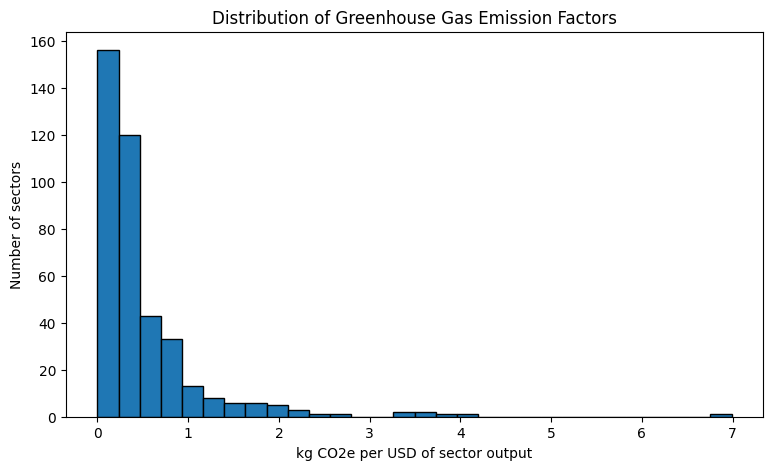

In [14]:
import matplotlib.pyplot as plt

# Plot a histogram to understand how emission factors are distributed.
plt.figure(figsize=(9, 5))

plt.hist(
    emission_factors_df["emission_factor"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Greenhouse Gas Emission Factors")
plt.xlabel("kg CO2e per USD of sector output")
plt.ylabel("Number of sectors")

plt.show()

In [15]:
# Sort sectors by emission factor, from highest to lowest.
top_10_sectors = emission_factors_df.sort_values(
    by="emission_factor",
    ascending=False
).head(10)

# Display their names and emission factors.
print(
    top_10_sectors[
        ["Name", "emission_factor", "Location"]
    ]
)

                                                  Name  emission_factor  \
42                                              Cement         6.988306   
249                                        Fertilizers         4.134417   
7                          Cattle ranches and feedlots         3.955616   
1            Fresh wheat, corn, rice, and other grains         3.722833   
46                            Lime and gypsum products         3.497837   
21                                         Electricity         3.441131   
6                                              Dairies         3.313138   
54                                    Primary aluminum         2.610529   
239                                   Compressed Gases         2.516659   
5    Tobacco, cotton, sugarcane, peanuts, sugar bee...         2.294222   

    Location  
42        US  
249       US  
7         US  
1         US  
46        US  
21        US  
6         US  
54        US  
239       US  
5         US  


In [16]:
import re

def clean_text(text):
    # Convert the input into a string.
    text = str(text)

    # Convert all characters to lowercase.
    text = text.lower()

    # Remove leading and trailing spaces.
    text = text.strip()

    # Replace punctuation with spaces, preserving letters and numbers.
    text = re.sub(r"[^\w\s]", " ", text)

    # Replace multiple consecutive spaces with a single space.
    text = re.sub(r"\s+", " ", text)

    # Return the cleaned description.
    return text

In [17]:
# Create a new column containing cleaned procurement descriptions.
# The original descriptions remain unchanged.
procurement_df["description_clean"] = (
    procurement_df["description"].apply(clean_text)
)

# Compare original and cleaned descriptions.
print(
    procurement_df[
        ["description", "description_clean"]
    ].head(10)
)

                        description                 description_clean
0   Laptop computer Lenovo ThinkPad   laptop computer lenovo thinkpad
1    Purchase of notebook computers    purchase of notebook computers
2                Office desk wooden                office desk wooden
3            Ergonomic office chair            ergonomic office chair
4  Diesel fuel for company vehicles  diesel fuel for company vehicles
5            Printer paper A4 80gsm            printer paper a4 80gsm
6    Copy paper for office printers    copy paper for office printers
7       Cloud software subscription       cloud software subscription
8            IT consulting services            it consulting services
9          Business travel by train          business travel by train


In [18]:
# Create a cleaned version of every EPA sector description.
emission_factors_df["sector_name_clean"] = (
    emission_factors_df["Name"].apply(clean_text)
)

# Display the original and cleaned sector descriptions.
print(
    emission_factors_df[
        ["Name", "sector_name_clean"]
    ].head(10)
)

                                                Name  \
0  Fresh soybeans, canola, flaxseeds, and other o...   
1          Fresh wheat, corn, rice, and other grains   
2             Fresh vegetables, melons, and potatoes   
3                         Fresh fruits and tree nuts   
4  Greenhouse crops, mushrooms, nurseries, and fl...   
5  Tobacco, cotton, sugarcane, peanuts, sugar bee...   
6                                            Dairies   
7                        Cattle ranches and feedlots   
8                                      Poultry farms   
9  Animal farms and aquaculture ponds (except cat...   

                                   sector_name_clean  
0  fresh soybeans canola flaxseeds and other oils...  
1             fresh wheat corn rice and other grains  
2               fresh vegetables melons and potatoes  
3                         fresh fruits and tree nuts  
4   greenhouse crops mushrooms nurseries and flowers  
5  tobacco cotton sugarcane peanuts sugar beets h... 

In [19]:
# Combine the sector name and broader economic category.
# This gives the matching algorithms more descriptive information.
emission_factors_df["matching_text"] = (
    emission_factors_df["Name"].fillna("") + " " +
    emission_factors_df["Category"].fillna("")
)

# Apply the same cleaning function.
emission_factors_df["matching_text_clean"] = (
    emission_factors_df["matching_text"].apply(clean_text)
)

# Inspect the result.
print(
    emission_factors_df[
        ["Name", "Category", "matching_text_clean"]
    ].head(10)
)

                                                Name  \
0  Fresh soybeans, canola, flaxseeds, and other o...   
1          Fresh wheat, corn, rice, and other grains   
2             Fresh vegetables, melons, and potatoes   
3                         Fresh fruits and tree nuts   
4  Greenhouse crops, mushrooms, nurseries, and fl...   
5  Tobacco, cotton, sugarcane, peanuts, sugar bee...   
6                                            Dairies   
7                        Cattle ranches and feedlots   
8                                      Poultry farms   
9  Animal farms and aquaculture ponds (except cat...   

                                            Category  \
0  11: Agriculture, Forestry, Fishing and Hunting...   
1  11: Agriculture, Forestry, Fishing and Hunting...   
2  11: Agriculture, Forestry, Fishing and Hunting...   
3  11: Agriculture, Forestry, Fishing and Hunting...   
4  11: Agriculture, Forestry, Fishing and Hunting...   
5  11: Agriculture, Forestry, Fishing and Hunti

In [20]:
# Install RapidFuzz if it is not already available.
!pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 16.0 MB/s  0:00:00


In [21]:
# Import the fuzzy matching functions.
from rapidfuzz import fuzz, process

# Select one procurement description.
query = procurement_df.loc[0, "description_clean"]

# Create a list containing all cleaned EPA sector descriptions.
choices = emission_factors_df["sector_name_clean"].tolist()

# Identify the three most similar EPA sectors.
matches = process.extract(
    query,
    choices,
    scorer=fuzz.ratio,
    limit=3
)

# Display the results.
print("Procurement description:", query)
print("\nTop three matches:")

for match in matches:
    print(match)

Procurement description: laptop computer lenovo thinkpad

Top three matches:
('custom computer programming', 51.72413793103448, 327)
('computer systems design', 48.14814814814815, 328)
('all other food and drinking places', 46.15384615384615, 377)


In [22]:
# Select the first procurement description.
query = procurement_df.loc[0, "description_clean"]

# Approach 1: Compare against sector names only.
name_matches = process.extract(
    query,
    emission_factors_df["sector_name_clean"].tolist(),
    scorer=fuzz.ratio,
    limit=3
)

# Approach 2: Compare against sector names and broader categories.
combined_matches = process.extract(
    query,
    emission_factors_df["matching_text_clean"].tolist(),
    scorer=fuzz.ratio,
    limit=3
)

# Display both sets of results.
print("MATCHING AGAINST SECTOR NAMES:")
for match in name_matches:
    print(match)

print("\nMATCHING AGAINST COMBINED TEXT:")
for match in combined_matches:
    print(match)

MATCHING AGAINST SECTOR NAMES:
('custom computer programming', 51.72413793103448, 327)
('computer systems design', 48.14814814814815, 328)
('all other food and drinking places', 46.15384615384615, 377)

MATCHING AGAINST COMBINED TEXT:
('scrap other activities ', 40.74074074074075, 398)
('customs duties 42 wholesale trade ', 40.0, 277)
('noncomparable imports other activities ', 37.142857142857146, 400)


In [23]:
def fuzzy_match(query, sector_data, limit=3):

    # Search the three most similar sector descriptions.
    matches = process.extract(
        query,
        sector_data["matching_text_clean"].tolist(),
        scorer=fuzz.ratio,
        limit=limit
    )

    # Store the matching results.
    results = []

    for match in matches:

        # Extract the matching text and similarity score.
        matched_text = match[0]
        score = match[1]

        # Find the corresponding row in the EPA dataset.
        sector = sector_data[
            sector_data["matching_text_clean"] == matched_text
        ].iloc[0]

        # Save the relevant information.
        results.append({
            "sector_name": sector["Name"],
            "sector_id": sector["ID"],
            "emission_factor": sector["emission_factor"],
            "similarity_score": score
        })

    return results

In [24]:
# Create an empty list to store the matching results.
all_matches = []

# Iterate through every procurement transaction.
for index, row in procurement_df.iterrows():

    # Extract the cleaned procurement description.
    query = row["description_clean"]

    # Find the three best matching EPA sectors.
    matches = fuzzy_match(
        query,
        emission_factors_df,
        limit=3
    )

    # Store the transaction ID, original description and candidates.
    for rank, match in enumerate(matches, start=1):

        all_matches.append({
            "transaction_id": row["transaction_id"],
            "procurement_description": row["description"],
            "rank": rank,
            "sector_name": match["sector_name"],
            "sector_id": match["sector_id"],
            "emission_factor": match["emission_factor"],
            "similarity_score": match["similarity_score"]
        })

# Convert the results into a Pandas DataFrame.
fuzzy_results_df = pd.DataFrame(all_matches)

# Display the first ten matching results.
print(fuzzy_results_df.head(10))

  transaction_id          procurement_description  rank  \
0          TR001  Laptop computer Lenovo ThinkPad     1   
1          TR001  Laptop computer Lenovo ThinkPad     2   
2          TR001  Laptop computer Lenovo ThinkPad     3   
3          TR002   Purchase of notebook computers     1   
4          TR002   Purchase of notebook computers     2   
5          TR002   Purchase of notebook computers     3   
6          TR003               Office desk wooden     1   
7          TR003               Office desk wooden     2   
8          TR003               Office desk wooden     3   
9          TR004           Ergonomic office chair     1   

                                sector_name  sector_id  emission_factor  \
0                                     Scrap  S00401/US         0.539245   
1                            Customs duties  4200ID/US         0.000000   
2                     Noncomparable imports  S00300/US         0.000000   
3                     Noncomparable imports  S0030

In [25]:
# Keep only the first-ranked candidate for each transaction.
best_fuzzy_matches = fuzzy_results_df[
    fuzzy_results_df["rank"] == 1
].copy()

# Sort the transactions by similarity score, from highest to lowest.
best_fuzzy_matches = best_fuzzy_matches.sort_values(
    by="similarity_score",
    ascending=False
)

# Display the procurement description and its best candidate.
print(
    best_fuzzy_matches[
        [
            "procurement_description",
            "sector_name",
            "similarity_score",
            "emission_factor"
        ]
    ].to_string(index=False)
)

         procurement_description                  sector_name  similarity_score  emission_factor
       Waste collection services   Other educational services         55.263158         0.116588
          IT consulting services   Other educational services         52.054795         0.116588
     Data storage cloud services   Other educational services         51.282051         0.116588
        Office cleaning services   Other educational services         48.000000         0.116588
        Printer toner cartridges                        Scrap         46.808511         0.539245
  Copy paper for office printers        Noncomparable imports         46.376812         0.000000
      Office stationery supplies            Gasoline stations         44.705882         0.273111
   Hotel accommodation employees                     Software         44.155844         0.051051
            Mobile phone devices        Noncomparable imports         44.067797         0.000000
  Purchase of notebook compute

In [26]:

# Convert text descriptions into numerical representations
from sklearn.feature_extraction.text import TfidfVectorizer

# Compare numerical representations using cosine similarity
from sklearn.metrics.pairwise import cosine_similarity

import pandas as pd


# Create the TF-IDF vectorizer
# It will learn which words are important across EPA sector names
tfidf_vectorizer = TfidfVectorizer()

# Learn the vocabulary and calculate TF-IDF values
# for all sector names in the EPA database
sector_tfidf = tfidf_vectorizer.fit_transform(
    emission_factors_df["sector_name_clean"]
)

# Convert procurement descriptions using the SAME vocabulary
procurement_tfidf = tfidf_vectorizer.transform(
    procurement_df["description_clean"]
)

# Check the dimensions of the resulting matrices
print("Sector matrix:", sector_tfidf.shape)
print("Procurement matrix:", procurement_tfidf.shape)


Sector matrix: (402, 797)
Procurement matrix: (25, 797)


In [27]:

# Calculate cosine similarity between every procurement description
# and every EPA sector name
similarity_matrix = cosine_similarity(
    procurement_tfidf,
    sector_tfidf
)

# Store the three best matches for each transaction
tfidf_results = []

for i, procurement_row in procurement_df.iterrows():

    # Get similarity scores for the current transaction
    scores = similarity_matrix[i]

    # Find the positions of the three highest scores
    top_indices = scores.argsort()[-3:][::-1]

    # Retrieve the corresponding EPA sectors
    for rank, sector_index in enumerate(top_indices, start=1):

        sector = emission_factors_df.iloc[sector_index]

        tfidf_results.append({
            "transaction_id": procurement_row["transaction_id"],
            "procurement_description": procurement_row["description"],
            "rank": rank,
            "sector_name": sector["Name"],
            "sector_id": sector["ID"],
            "emission_factor": sector["emission_factor"],
            "similarity_score": scores[sector_index]
        })

# Convert results into a DataFrame
tfidf_results_df = pd.DataFrame(tfidf_results)

# Display the results
print("Number of matching results:", len(tfidf_results_df))

tfidf_results_df.head(15)


Number of matching results: 75


,transaction_id,procurement_description,rank,sector_name,sector_id,emission_factor,similarity_score
0,TR001,Laptop computer Lenovo ThinkPad,1,Computer terminals and other computer peripher...,334118/US,0.175382,0.713783
1,TR001,Laptop computer Lenovo ThinkPad,2,Custom computer programming,541511/US,0.084490,0.538714
2,TR001,Laptop computer Lenovo ThinkPad,3,Computer systems design,541512/US,0.085006,0.529412
3,TR002,Purchase of notebook computers,1,Computers,334111/US,0.049985,0.746968
4,TR002,Purchase of notebook computers,2,Rest of the world adjustment,S00900/US,0.253349,0.273907
5,TR002,Purchase of notebook computers,3,Lessors of nonfinancial intangible assets,533000/US,0.061292,0.270327
6,TR003,Office desk wooden,1,Office administration,561100/US,0.102967,0.442038
7,TR003,Office desk wooden,2,"Wooden windows, door, and flooring",321910/US,0.299913,0.376138
8,TR003,Office desk wooden,3,Office supplies (not paper),339940/US,0.368948,0.339239
9,TR004,Ergonomic office chair,1,Office administration,561100/US,0.102967,0.664860


In [28]:

# Keep only the highest-ranked sector for each transaction
tfidf_best_matches = tfidf_results_df[
    tfidf_results_df["rank"] == 1
].copy()

# Display the results in a readable format
print(
    tfidf_best_matches[
        [
            "procurement_description",
            "sector_name",
            "similarity_score",
            "emission_factor"
        ]
    ].to_string(index=False)
)


         procurement_description                                                sector_name  similarity_score  emission_factor
 Laptop computer Lenovo ThinkPad Computer terminals and other computer peripheral equipment          0.713783         0.175382
  Purchase of notebook computers                                                  Computers          0.746968         0.049985
              Office desk wooden                                      Office administration          0.442038         0.102967
          Ergonomic office chair                                      Office administration          0.664860         0.102967
Diesel fuel for company vehicles                          Company and enterprise management          0.395550         0.086653
          Printer paper A4 80gsm                                                      Paper          1.000000         1.245453
  Copy paper for office printers                                Office supplies (not paper)          0.570615  

In [29]:
# Save the matching results in the processed data folder
tfidf_results_df.to_csv(
    "/content/scope3-procurement-matching/data/processed/tfidf_matching_results.csv",
    index=False
)

In [30]:
# Install the library used to generate semantic embeddings
!pip install -q sentence-transformers

# Import the sentence-transformer model
from sentence_transformers import SentenceTransformer

# Load a pre-trained model for comparing sentence meanings
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [31]:
# Convert each procurement description into a numerical vector
procurement_embeddings = embedding_model.encode(
    procurement_df["description_clean"].tolist(),
    convert_to_tensor=True,
    normalize_embeddings=True
)

# Convert each EPA sector name into a numerical vector
sector_embeddings = embedding_model.encode(
    emission_factors_df["sector_name_clean"].tolist(),
    convert_to_tensor=True,
    normalize_embeddings=True
)

# Check the dimensions of the resulting matrices
print("Procurement embeddings:", procurement_embeddings.shape)
print("Sector embeddings:", sector_embeddings.shape)

Procurement embeddings: torch.Size([25, 384])
Sector embeddings: torch.Size([402, 384])


In [32]:
# Calculate cosine similarity between all procurement descriptions
# and all EPA sector names
# Because we normalized the embeddings, multiplying the first matrix by the
# transpose of the second calculates cosine similarity.

semantic_similarity_matrix = (
    procurement_embeddings @ sector_embeddings.T
)

print("Similarity matrix:", semantic_similarity_matrix.shape)

Similarity matrix: torch.Size([25, 402])


In [33]:
# Store the three best semantic matches for each transaction
semantic_results = []

for i, procurement_row in procurement_df.iterrows():

    # Get similarity scores for the current procurement description
    scores = semantic_similarity_matrix[i]

    # Find the positions of the three highest scores
    top_indices = scores.argsort(descending=True)[:3]

    # Retrieve the corresponding EPA sectors
    for rank, sector_index in enumerate(top_indices.tolist(), start=1):

        sector = emission_factors_df.iloc[sector_index]

        semantic_results.append({
            "transaction_id": procurement_row["transaction_id"],
            "procurement_description": procurement_row["description"],
            "rank": rank,
            "sector_name": sector["Name"],
            "sector_id": sector["ID"],
            "emission_factor": sector["emission_factor"],
            "similarity_score": scores[sector_index].item()
        })

# Convert results into a DataFrame
semantic_results_df = pd.DataFrame(semantic_results)

print("Number of matching results:", len(semantic_results_df))

Number of matching results: 75


In [34]:
# Keep only the highest-ranked sector for each transaction
semantic_best_matches = semantic_results_df[
    semantic_results_df["rank"] == 1
].copy()

# Display the results
print(
    semantic_best_matches[
        [
            "procurement_description",
            "sector_name",
            "similarity_score",
            "emission_factor"
        ]
    ].to_string(index=False)
)

         procurement_description                                                      sector_name  similarity_score  emission_factor
 Laptop computer Lenovo ThinkPad                                                        Computers          0.363579         0.049985
  Purchase of notebook computers                                                        Computers          0.457448         0.049985
              Office desk wooden  Office furniture and custom architectural woodwork and millwork          0.628094         0.337602
          Ergonomic office chair  Office furniture and custom architectural woodwork and millwork          0.391365         0.337602
Diesel fuel for company vehicles           Gasoline, fuels, and by-products of petroleum refining          0.509096         0.917141
          Printer paper A4 80gsm                                                 Printing support          0.497878         0.262486
  Copy paper for office printers                                     

In [35]:
# Save semantic matching results for the final comparison
semantic_results_df.to_csv(
    "/content/scope3-procurement-matching/data/processed/semantic_matching_results.csv",
    index=False
)

In [46]:

# Keep only the best match from each algorithm
fuzzy_best = fuzzy_results_df[
    fuzzy_results_df["rank"] == 1
][["transaction_id", "sector_name"]].rename(
    columns={"sector_name": "fuzzy_match"}
)

tfidf_best = tfidf_results_df[
    tfidf_results_df["rank"] == 1
][["transaction_id", "sector_name"]].rename(
    columns={"sector_name": "tfidf_match"}
)

semantic_best = semantic_results_df[
    semantic_results_df["rank"] == 1
][["transaction_id", "sector_name"]].rename(
    columns={"sector_name": "semantic_match"}
)

# Combine the three methods into one comparison table
comparison_df = fuzzy_best.merge(
    tfidf_best, on="transaction_id"
).merge(
    semantic_best, on="transaction_id"
)

# Add the original procurement descriptions
comparison_df = comparison_df.merge(
    procurement_df[["transaction_id", "description"]],
    on="transaction_id"
)

# Display the comparison
comparison_df = comparison_df[
    ["transaction_id", "description",
     "fuzzy_match", "tfidf_match", "semantic_match"]
]

display(comparison_df)


,transaction_id,description,fuzzy_match,tfidf_match,semantic_match
0,TR001,Laptop computer Lenovo ThinkPad,Scrap,Computer terminals and other computer peripheral equipment,Computers
1,TR002,Purchase of notebook computers,Noncomparable imports,Computers,Computers
2,TR003,Office desk wooden,Customs duties,Office administration,Office furniture and custom architectural woodwork and millwork
3,TR004,Ergonomic office chair,Noncomparable imports,Office administration,Office furniture and custom architectural woodwork and millwork
4,TR005,Diesel fuel for company vehicles,Rest of the world adjustment,Company and enterprise management,"Gasoline, fuels, and by-products of petroleum refining"
5,TR006,Printer paper A4 80gsm,Paper,Paper,Printing support
6,TR007,Copy paper for office printers,Noncomparable imports,Office supplies (not paper),Office supplies (not paper)
7,TR008,Cloud software subscription,Software,Software,Cable and subscription programming
8,TR009,IT consulting services,Other educational services,Management consulting,Management consulting
9,TR010,Business travel by train,Customs duties,Business support,Rail transport


In [49]:
# Create manually reviewed reference classifications
ground_truth = pd.DataFrame({
    "transaction_id": [
        "TR001", "TR002", "TR003", "TR004", "TR005",
        "TR006", "TR007", "TR008", "TR009", "TR010",
        "TR011", "TR012", "TR013", "TR014", "TR015",
        "TR016", "TR017", "TR018", "TR019", "TR020",
        "TR021", "TR022", "TR023", "TR024", "TR025"
    ],
    "reference_sector": [
        "Computers",
        "Computers",
        "Office furniture",
        "Office furniture",
        "Gasoline, fuels, and by-products of petroleum refining",
        "Paper",
        "Paper",
        "Software",
        "Management consulting",
        "Rail transport",
        "Hotels and campgrounds",
        "Office cleaning/janitorial services",
        "Electricity",
        "Communications equipment",
        "Computers",
        "Office furniture",
        "Computers",
        "Gasoline, fuels, and by-products of petroleum refining",
        "Ink and ink cartridges",
        "Waste management and remediation",
        "Legal services",
        "Data processing and hosting",
        "Stationery",
        "Air transportation",
        "Electronic equipment repair and maintenance"
    ]
})

display(ground_truth)

,transaction_id,reference_sector
0,TR001,Computers
1,TR002,Computers
2,TR003,Office furniture
3,TR004,Office furniture
4,TR005,"Gasoline, fuels, and by-products of petroleum refining"
5,TR006,Paper
6,TR007,Paper
7,TR008,Software
8,TR009,Management consulting
9,TR010,Rail transport


In [50]:
# Merge predictions with manually verified reference classifications
evaluation_df = comparison_df.merge(
    ground_truth,
    on="transaction_id"
)

# Calculate Top-1 accuracy for each method
methods = ["fuzzy_match", "tfidf_match", "semantic_match"]

for method in methods:

    accuracy = (
        evaluation_df[method] == evaluation_df["reference_sector"]
    ).mean()

    print(f"{method}: {accuracy:.1%}")

fuzzy_match: 8.0%
tfidf_match: 36.0%
semantic_match: 60.0%


In [52]:
# Store Top-3 accuracy results
top3_results = {}

# Evaluate each matching method
for method, results_df in [
    ("Fuzzy", fuzzy_results_df),
    ("TF-IDF", tfidf_results_df),
    ("Semantic", semantic_results_df)
]:

    # Attach the reference classification to each suggestion
    evaluated = results_df.merge(
        ground_truth,
        on="transaction_id"
    )

    # Check whether the correct sector appears in the top 3
    correct = evaluated[
        evaluated["sector_name"] == evaluated["reference_sector"]
    ]["transaction_id"].nunique()

    top3_results[method] = correct / len(ground_truth)

# Display results
for method, accuracy in top3_results.items():
    print(f"{method} Top-3 accuracy: {accuracy:.1%}")


Fuzzy Top-3 accuracy: 12.0%
TF-IDF Top-3 accuracy: 44.0%
Semantic Top-3 accuracy: 72.0%


In [56]:
# Create a summary of the evaluation results
evaluation_summary = pd.DataFrame({
    "Method": ["Fuzzy", "TF-IDF", "Semantic"],
    "Top-1 Accuracy": [
        (fuzzy_best["fuzzy_match"].values == ground_truth["reference_sector"].values).mean(),
        (tfidf_best["tfidf_match"].values == ground_truth["reference_sector"].values).mean(),
        (semantic_best["semantic_match"].values == ground_truth["reference_sector"].values).mean()
    ],
    "Top-3 Accuracy": [
        top3_results["Fuzzy"],
        top3_results["TF-IDF"],
        top3_results["Semantic"]
    ]
})

# Save the dynamically calculated results
evaluation_summary.to_csv(
    "/content/scope3-procurement-matching/results/method_comparison.csv",
    index=False
)

display(evaluation_summary)

,Method,Top-1 Accuracy,Top-3 Accuracy
0,Fuzzy,0.08,0.12
1,TF-IDF,0.36,0.44
2,Semantic,0.60,0.72


In [59]:

# Start with the three best semantic matches
final_matching_df = semantic_results_df.copy()

# Calculate the difference between the first and second match scores
best_scores = (
    final_matching_df[final_matching_df["rank"] == 1]
    [["transaction_id", "similarity_score"]]
    .rename(columns={"similarity_score": "best_score"})
)

second_scores = (
    final_matching_df[final_matching_df["rank"] == 2]
    [["transaction_id", "similarity_score"]]
    .rename(columns={"similarity_score": "second_best_score"})
)

# Combine the scores
score_comparison = best_scores.merge(
    second_scores, on="transaction_id"
)

score_comparison["score_margin"] = (
    score_comparison["best_score"] -
    score_comparison["second_best_score"]
)

# Keep the top-ranked suggestion for each transaction
final_matching_df = final_matching_df[
    final_matching_df["rank"] == 1
].copy()

# Add the score comparison
final_matching_df = final_matching_df.merge(
    score_comparison, on="transaction_id"
)

# Flag predictions for human validation
final_matching_df["review_status"] = "Manual review required"

# Save the final matching output
final_matching_df.to_csv(
    "/content/scope3-procurement-matching/results/final_matching_results.csv",
    index=False
)

display(final_matching_df[
    [
        "transaction_id",
        "procurement_description",
        "sector_name",
        "similarity_score",
        "score_margin",
        "review_status"
    ]
])


,transaction_id,procurement_description,sector_name,similarity_score,score_margin,review_status
0,TR001,Laptop computer Lenovo ThinkPad,Computers,0.363579,0.086265,Manual review required
1,TR002,Purchase of notebook computers,Computers,0.457448,0.013367,Manual review required
2,TR003,Office desk wooden,Office furniture and custom architectural woodwork and millwork,0.628094,0.101346,Manual review required
3,TR004,Ergonomic office chair,Office furniture and custom architectural woodwork and millwork,0.391365,0.000995,Manual review required
4,TR005,Diesel fuel for company vehicles,"Gasoline, fuels, and by-products of petroleum refining",0.509096,0.038819,Manual review required
5,TR006,Printer paper A4 80gsm,Printing support,0.497878,0.004372,Manual review required
6,TR007,Copy paper for office printers,Office supplies (not paper),0.627935,0.017255,Manual review required
7,TR008,Cloud software subscription,Cable and subscription programming,0.545810,0.225223,Manual review required
8,TR009,IT consulting services,Management consulting,0.720616,0.115341,Manual review required
9,TR010,Business travel by train,Rail transport,0.641824,0.089672,Manual review required


In [60]:
# Retrieve the emission factor associated with each predicted sector
final_matching_df = final_matching_df.merge(
    emission_factors_df[["ID", "emission_factor"]],
    left_on="sector_id",
    right_on="ID",
    how="left"
)

# Add the procurement expenditure
final_matching_df = final_matching_df.merge(
    procurement_df[["transaction_id", "amount", "currency"]],
    on="transaction_id",
    how="left"
)

# Display the resulting dataset
display(
    final_matching_df[
        [
            "transaction_id",
            "procurement_description",
            "sector_name",
            "emission_factor",
            "amount",
            "currency"
        ]
    ]
)

KeyError: "['emission_factor'] not in index"

In [61]:
print("Emission factors columns:")
print(emission_factors_df.columns.tolist())

print("\nFinal matching columns:")
print(final_matching_df.columns.tolist())

Emission factors columns:
['ID', 'emission_factor', 'Name', 'Code', 'Location', 'Category', 'Unit', 'indicator', 'factor_unit', 'sector_name_clean', 'matching_text', 'matching_text_clean']

Final matching columns:
['transaction_id', 'procurement_description', 'rank', 'sector_name', 'sector_id', 'emission_factor_x', 'similarity_score', 'best_score', 'second_best_score', 'score_margin', 'review_status', 'ID', 'emission_factor_y', 'amount', 'currency']


In [66]:
# Keep the relevant matching information
final_matching_clean = final_matching_df[
    [
        "transaction_id",
        "procurement_description",
        "sector_name",
        "sector_id",
        "similarity_score",
        "score_margin",
        "review_status"
    ]
].copy()

# Retrieve the official emission factors using EPA sector IDs
factor_lookup = emission_factors_df[
    ["ID", "emission_factor"]
].rename(columns={"ID": "sector_id"})

final_matching_clean = final_matching_clean.merge(
    factor_lookup,
    on="sector_id",
    how="left",
    validate="many_to_one"
)

# Add procurement expenditure and currency
final_matching_clean = final_matching_clean.merge(
    procurement_df[["transaction_id", "amount", "currency"]],
    on="transaction_id",
    how="left"
)

# Replace the previous DataFrame with the clean version
final_matching_df = final_matching_clean

display(final_matching_df)

,transaction_id,procurement_description,sector_name,sector_id,similarity_score,score_margin,review_status,emission_factor,amount,currency
0,TR001,Laptop computer Lenovo ThinkPad,Computers,334111/US,0.363579,0.086265,Manual review required,0.049985,1450,CHF
1,TR002,Purchase of notebook computers,Computers,334111/US,0.457448,0.013367,Manual review required,0.049985,3200,CHF
2,TR003,Office desk wooden,Office furniture and custom architectural woodwork and millwork,33721A/US,0.628094,0.101346,Manual review required,0.337602,850,CHF
3,TR004,Ergonomic office chair,Office furniture and custom architectural woodwork and millwork,33721A/US,0.391365,0.000995,Manual review required,0.337602,420,CHF
4,TR005,Diesel fuel for company vehicles,"Gasoline, fuels, and by-products of petroleum refining",324110/US,0.509096,0.038819,Manual review required,0.917141,780,CHF
5,TR006,Printer paper A4 80gsm,Printing support,323120/US,0.497878,0.004372,Manual review required,0.262486,120,CHF
6,TR007,Copy paper for office printers,Office supplies (not paper),339940/US,0.627935,0.017255,Manual review required,0.368948,95,CHF
7,TR008,Cloud software subscription,Cable and subscription programming,515200/US,0.545810,0.225223,Manual review required,0.109095,2400,CHF
8,TR009,IT consulting services,Management consulting,541610/US,0.720616,0.115341,Manual review required,0.077180,5500,CHF
9,TR010,Business travel by train,Rail transport,482000/US,0.641824,0.089672,Manual review required,0.561614,180,CHF


In [63]:
print("Total transactions:", len(final_matching_df))
print("Missing emission factors:", final_matching_df["emission_factor"].isna().sum())
print("Missing expenditure amounts:", final_matching_df["amount"].isna().sum())

Total transactions: 25
Missing emission factors: 0
Missing expenditure amounts: 0


In [67]:
# Calculate the median similarity score and score margin
median_score = final_matching_df["similarity_score"].median()
median_margin = final_matching_df["score_margin"].median()

# Create a review priority for each transaction
final_matching_df["review_priority"] = "Normal"

final_matching_df.loc[
    (final_matching_df["similarity_score"] < median_score) |
    (final_matching_df["score_margin"] < median_margin),
    "review_priority"
] = "High"

# Display transactions requiring priority review
display(
    final_matching_df[
        ["transaction_id", "procurement_description",
         "sector_name", "similarity_score",
         "score_margin", "review_priority"]
    ].sort_values(
        by=["review_priority", "score_margin"],
        ascending=[True, True]
    )
)

,transaction_id,procurement_description,sector_name,similarity_score,score_margin,review_priority
15,TR016,Office furniture cabinets,Office furniture and custom architectural woodwork and millwork,0.717454,0.000841,High
13,TR014,Mobile phone devices,Communications equipment,0.510465,0.000866,High
3,TR004,Ergonomic office chair,Office furniture and custom architectural woodwork and millwork,0.391365,0.000995,High
17,TR018,Petrol for company cars,"Gasoline, fuels, and by-products of petroleum refining",0.573821,0.004243,High
5,TR006,Printer paper A4 80gsm,Printing support,0.497878,0.004372,High
20,TR021,Professional legal consulting,Legal services,0.628217,0.006265,High
1,TR002,Purchase of notebook computers,Computers,0.457448,0.013367,High
6,TR007,Copy paper for office printers,Office supplies (not paper),0.627935,0.017255,High
23,TR024,Business travel by airplane,Aircraft,0.515220,0.035129,High
4,TR005,Diesel fuel for company vehicles,"Gasoline, fuels, and by-products of petroleum refining",0.509096,0.038819,High


In [69]:
# Create a separate table for the manual review process
review_queue_df = final_matching_df.copy()

# Add empty columns for the reviewer's decisions
review_queue_df["approved_sector"] = ""
review_queue_df["review_decision"] = "Pending"
review_queue_df["reviewer_notes"] = ""

# Keep only the columns needed for reviewing
review_queue_df = review_queue_df[
    [
        "transaction_id",
        "procurement_description",
        "sector_name",
        "sector_id",
        "similarity_score",
        "score_margin",
        "review_priority",
        "approved_sector",
        "review_decision",
        "reviewer_notes"
    ]
]

# Save the review template
review_queue_df.to_csv(
    "/content/scope3-procurement-matching/results/review_queue.csv",
    index=False
)

display(review_queue_df)

,transaction_id,procurement_description,sector_name,sector_id,similarity_score,score_margin,review_priority,approved_sector,review_decision,reviewer_notes
0,TR001,Laptop computer Lenovo ThinkPad,Computers,334111/US,0.363579,0.086265,High,,Pending,
1,TR002,Purchase of notebook computers,Computers,334111/US,0.457448,0.013367,High,,Pending,
2,TR003,Office desk wooden,Office furniture and custom architectural woodwork and millwork,33721A/US,0.628094,0.101346,Normal,,Pending,
3,TR004,Ergonomic office chair,Office furniture and custom architectural woodwork and millwork,33721A/US,0.391365,0.000995,High,,Pending,
4,TR005,Diesel fuel for company vehicles,"Gasoline, fuels, and by-products of petroleum refining",324110/US,0.509096,0.038819,High,,Pending,
5,TR006,Printer paper A4 80gsm,Printing support,323120/US,0.497878,0.004372,High,,Pending,
6,TR007,Copy paper for office printers,Office supplies (not paper),339940/US,0.627935,0.017255,High,,Pending,
7,TR008,Cloud software subscription,Cable and subscription programming,515200/US,0.545810,0.225223,High,,Pending,
8,TR009,IT consulting services,Management consulting,541610/US,0.720616,0.115341,Normal,,Pending,
9,TR010,Business travel by train,Rail transport,482000/US,0.641824,0.089672,Normal,,Pending,


In [75]:
def match_procurement_data(new_procurement_df, sector_data, model, sector_vectors):

    # Preserve the original procurement data
    data = new_procurement_df.copy()

    # Clean procurement descriptions
    data["description_clean"] = data["description"].apply(clean_text)

    # Convert descriptions into numerical embeddings
    procurement_vectors = model.encode(
        data["description_clean"].tolist(),
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    # Compare procurement descriptions with the sector database
    similarity_matrix = procurement_vectors @ sector_vectors.T

    results = []

    # Find the three best sector candidates for each transaction
    for i, row in data.reset_index(drop=True).iterrows():

        scores = similarity_matrix[i].cpu().numpy()
        top_indices = scores.argsort()[-3:][::-1]

        for rank, sector_index in enumerate(top_indices, start=1):

            sector = sector_data.iloc[sector_index]

            results.append({
                "transaction_id": row["transaction_id"],
                "procurement_description": row["description"],
                "rank": rank,
                "sector_name": sector["Name"],
                "sector_id": sector["ID"],
                "similarity_score": scores[sector_index]
            })

    return pd.DataFrame(results)

test_results = match_procurement_data(
    new_procurement_df=procurement_df,
    sector_data=emission_factors_df,
    model=embedding_model,
    sector_vectors=sector_embeddings
)

display(test_results.head(10))

,transaction_id,procurement_description,rank,sector_name,sector_id,similarity_score
0,TR001,Laptop computer Lenovo ThinkPad,1,Computers,334111/US,0.363579
1,TR001,Laptop computer Lenovo ThinkPad,2,Computer terminals and other computer peripheral equipment,334118/US,0.277314
2,TR001,Laptop computer Lenovo ThinkPad,3,Machine shops,332710/US,0.253368
3,TR002,Purchase of notebook computers,1,Computers,334111/US,0.457448
4,TR002,Purchase of notebook computers,2,Machine shops,332710/US,0.444081
5,TR002,Purchase of notebook computers,3,Computer terminals and other computer peripheral equipment,334118/US,0.365393
6,TR003,Office desk wooden,1,Office furniture and custom architectural woodwork and millwork,33721A/US,0.628094
7,TR003,Office desk wooden,2,Wood pulp,322110/US,0.526749
8,TR003,Office desk wooden,3,Institutional furniture,337127/US,0.516254
9,TR004,Ergonomic office chair,1,Office furniture and custom architectural woodwork and millwork,33721A/US,0.391365


In [76]:
# Save the matching function in the src folder
import inspect

function_code = inspect.getsource(match_procurement_data)

with open(
    "/content/scope3-procurement-matching/src/matching.py",
    "w"
) as file:
    file.write(function_code)

In [77]:
import shutil

shutil.make_archive(
    "/content/scope3-procurement-matching",
    "zip",
    "/content/scope3-procurement-matching"
)

'/content/scope3-procurement-matching.zip'